# CSE498V2: Eye Disease Classification + XAI + Federated Learning


In [13]:
# 1) Optional: install missing packages (safe to re-run)
import importlib
import subprocess
import sys


def ensure_package(import_name: str, pip_name: str | None = None):
    try:
        importlib.import_module(import_name)
    except Exception:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pip_name or import_name])


ensure_package("timm")
ensure_package("pytorch_grad_cam", "grad-cam")


In [14]:
# 2) Imports and global config
import os
import copy
import time
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

import torchvision
from torchvision import transforms
from PIL import Image

import timm

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report


In [15]:
# 3) Paths and runtime setup
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DATASET_DIR = Path(r"D:\NSU Course\2026\CSE498R\Eye Disease Image Dataset\Eye Disease Image Dataset\Augmented Dataset\Augmented Dataset")
PROJECT_DIR = Path(r"D:\CSE Code\CSE498R")
MODEL_DIR = PROJECT_DIR / "CSE498R models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

if not DATASET_DIR.exists():
    raise FileNotFoundError(f"Dataset directory not found: {DATASET_DIR}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Dataset:", DATASET_DIR)
print("Model output:", MODEL_DIR)


Device: cuda
Dataset: D:\NSU Course\2026\CSE498R\Eye Disease Image Dataset\Eye Disease Image Dataset\Augmented Dataset\Augmented Dataset
Model output: D:\CSE Code\CSE498R\CSE498R models


In [16]:
# 3b) Device check: which backend PyTorch will use for training
import torch

cuda_ok = torch.cuda.is_available()
print("torch.cuda.is_available():", cuda_ok)
if cuda_ok:
    print("Using: GPU (CUDA)")
    print("  device count:", torch.cuda.device_count())
    print("  current device:", torch.cuda.current_device())
    print("  name:", torch.cuda.get_device_name(0))
else:
    print("Using: CPU (no CUDA device visible to PyTorch)")

print("torch.version.cuda (build):", torch.version.cuda)
print("Recommended training device for this notebook:", "cuda" if cuda_ok else "cpu")


torch.cuda.is_available(): True
Using: GPU (CUDA)
  device count: 1
  current device: 0
  name: NVIDIA GeForce GTX 1650
torch.version.cuda (build): 11.8
Recommended training device for this notebook: cuda


In [17]:
# 4) Build image index
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

class_dirs = [d for d in sorted(DATASET_DIR.iterdir()) if d.is_dir()]
if not class_dirs:
    raise RuntimeError(f"No class folders found in: {DATASET_DIR}")

class_names = [d.name for d in class_dirs]
class_to_idx = {c: i for i, c in enumerate(class_names)}

rows = []
for class_dir in class_dirs:
    label_name = class_dir.name
    label_idx = class_to_idx[label_name]
    for p in class_dir.rglob("*"):
        if p.is_file() and p.suffix.lower() in VALID_EXTS:
            rows.append((str(p), label_idx, label_name))

df = pd.DataFrame(rows, columns=["path", "label", "class_name"])
if df.empty:
    raise RuntimeError("No images found in dataset.")

print("Total images:", len(df))
print("Total classes:", len(class_names))
display(df["class_name"].value_counts().sort_index())


Total images: 16242
Total classes: 10


class_name
Central Serous Chorioretinopathy [Color Fundus]     606
Diabetic Retinopathy                               3444
Disc Edema                                          762
Glaucoma                                           2880
Healthy                                            2676
Macular Scar                                       1937
Myopia                                             2251
Pterygium                                           102
Retinal Detachment                                  750
Retinitis Pigmentosa                                834
Name: count, dtype: int64

## Dataset samples by class

Below: **one random image per class** from the full image index (before the train/val/test split), so you can visually scan every disease or category type.


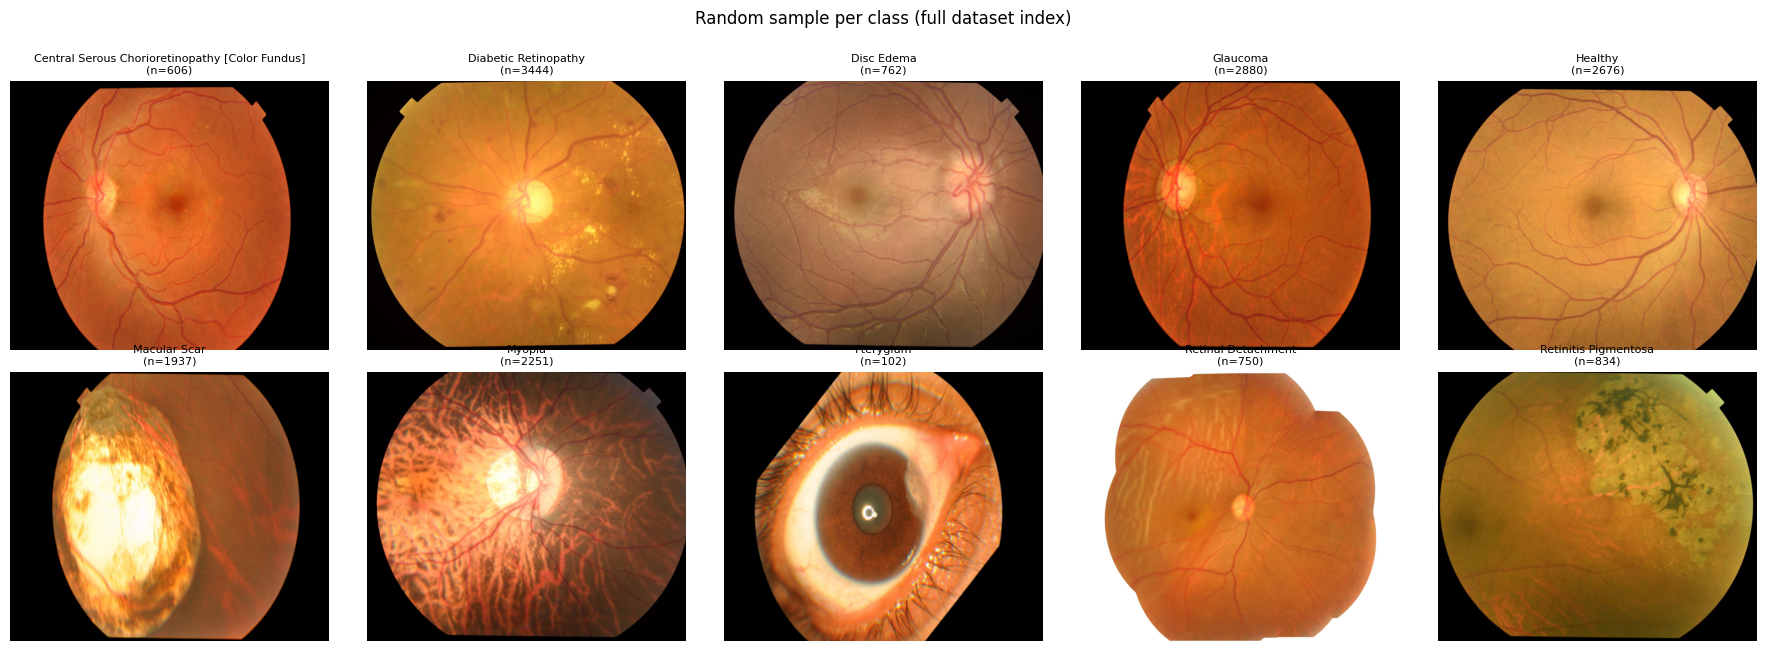

In [18]:
# 4b) Visualize dataset images: one sample per class (all types)
import math

rng = np.random.default_rng(SEED)
n_classes = len(class_names)
cols = min(5, n_classes)
rows = math.ceil(n_classes / cols)

fig, axes = plt.subplots(rows, cols, figsize=(3.6 * cols, 3.2 * rows))
axes = np.atleast_1d(axes).ravel()

for i, cname in enumerate(class_names):
    ax = axes[i]
    subset = df[df["class_name"] == cname]
    if subset.empty:
        ax.text(0.5, 0.5, "no images", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(cname, fontsize=8)
        ax.axis("off")
        continue
    pick = int(rng.integers(0, len(subset)))
    path = subset.iloc[pick]["path"]
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{cname}\n(n={len(subset)})", fontsize=8)
    ax.axis("off")

for j in range(n_classes, len(axes)):
    axes[j].axis("off")

plt.suptitle("Random sample per class (full dataset index)", fontsize=12, y=1.01)
plt.tight_layout()
plt.show()


In [19]:
# 5) Stratified train/val/test split (70/15/15)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=SEED,
    stratify=df["label"],
)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"],
)

print("Train:", len(train_df), "Val:", len(val_df), "Test:", len(test_df))


Train: 11369 Val: 2436 Test: 2437


C:\Users\mdsha\AppData\Local\Temp\ipykernel_22180\1402975723.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
C:\Users\mdsha\AppData\Local\Temp\ipykernel_22180\1402975723.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
C:\Users\mdsha\AppData\Local\Temp\ipykernel_22180\1402975723.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


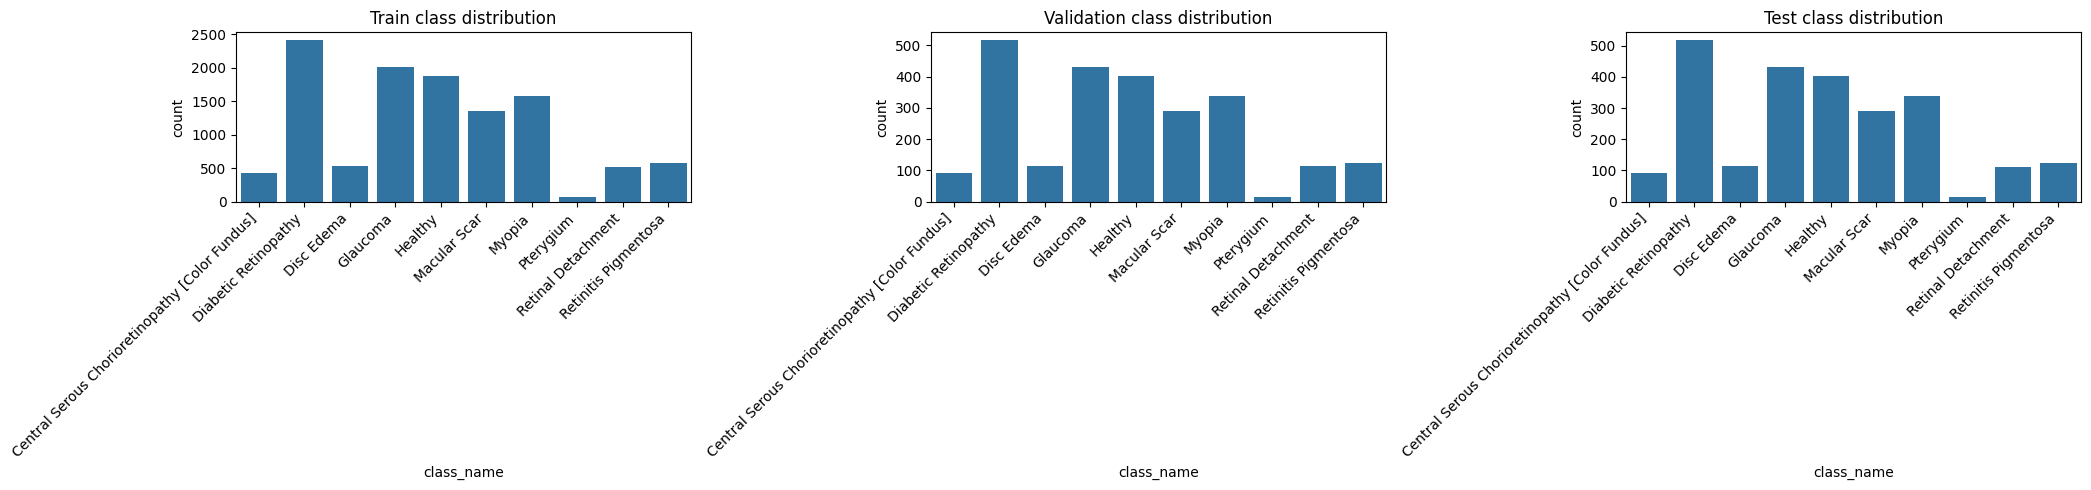

In [20]:
# 6) Visualize split distribution
fig, axes = plt.subplots(1, 3, figsize=(21, 5))
for ax, data, title in zip(
    axes,
    [train_df, val_df, test_df],
    ["Train", "Validation", "Test"],
):
    vc = data["class_name"].value_counts().sort_index()
    sns.barplot(x=vc.index, y=vc.values, ax=ax)
    ax.set_title(f"{title} class distribution")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_ylabel("count")
plt.tight_layout()
plt.show()


In [21]:
# 7) Dataset + transforms
IMG_SIZE = 224
INCEPTION_SIZE = 299
BATCH_SIZE = 16 if torch.cuda.is_available() else 8
NUM_WORKERS = 0  # stable in Windows notebooks
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


class EyeDiseaseDataset(Dataset):
    def __init__(self, data_df: pd.DataFrame, transform=None):
        self.data_df = data_df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data_df)

    def __getitem__(self, idx):
        row = self.data_df.iloc[idx]
        image = Image.open(row["path"]).convert("RGB")
        label = int(row["label"])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

inception_train_tfms = transforms.Compose([
    transforms.Resize((INCEPTION_SIZE, INCEPTION_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

inception_eval_tfms = transforms.Compose([
    transforms.Resize((INCEPTION_SIZE, INCEPTION_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


In [22]:
# 8) DataLoaders with class balancing
train_dataset = EyeDiseaseDataset(train_df, transform=train_tfms)
val_dataset = EyeDiseaseDataset(val_df, transform=eval_tfms)
test_dataset = EyeDiseaseDataset(test_df, transform=eval_tfms)

inception_train_dataset = EyeDiseaseDataset(train_df, transform=inception_train_tfms)
inception_val_dataset = EyeDiseaseDataset(val_df, transform=inception_eval_tfms)
inception_test_dataset = EyeDiseaseDataset(test_df, transform=inception_eval_tfms)

label_counts = Counter(train_df["label"].tolist())
sample_weights = [1.0 / label_counts[int(lbl)] for lbl in train_df["label"].tolist()]
sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True,
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

inception_train_loader = DataLoader(inception_train_dataset, batch_size=BATCH_SIZE, sampler=sampler, num_workers=NUM_WORKERS)
inception_val_loader = DataLoader(inception_val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
inception_test_loader = DataLoader(inception_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print("Data loaders are ready.")


Data loaders are ready.


In [23]:
# 9) Model builders
NUM_CLASSES = len(class_names)


def create_resnet50(num_classes: int):
    model = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def create_efficientnet_b0(num_classes: int):
    model = torchvision.models.efficientnet_b0(weights=torchvision.models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    return model


def create_densenet121(num_classes: int):
    model = torchvision.models.densenet121(weights=torchvision.models.DenseNet121_Weights.IMAGENET1K_V1)
    model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    return model


def create_mobilenet_v3_small(num_classes: int):
    model = torchvision.models.mobilenet_v3_small(weights=torchvision.models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
    model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, num_classes)
    return model


def create_vit_base(num_classes: int):
    model = timm.create_model("vit_base_patch16_224", pretrained=True)
    if hasattr(model, "head") and isinstance(model.head, nn.Linear):
        model.head = nn.Linear(model.head.in_features, num_classes)
    return model


In [24]:
# 10) Training / evaluation helpers
from tqdm.auto import tqdm

EPOCHS = 10 if torch.cuda.is_available() else 4
SHOW_TRAIN_PROGRESS = True  # tqdm batch bar during each epoch; set False for epoch-end logs only
PROGRESS_LOG_INTERVAL = 50  # when SHOW_TRAIN_PROGRESS is False, print every N batches (heartbeat)
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-4

class_weights_np = []
for i in range(NUM_CLASSES):
    class_weights_np.append(len(train_df) / (NUM_CLASSES * max(label_counts[i], 1)))
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)


def unwrap_logits(outputs):
    if isinstance(outputs, torch.Tensor):
        return outputs
    if hasattr(outputs, "logits"):
        return outputs.logits
    if isinstance(outputs, (tuple, list)):
        return outputs[0]
    return outputs


def evaluate_model(model, loader):
    model.eval()
    y_true, y_pred = [], []
    running_loss = 0.0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = unwrap_logits(model(x))
            loss = criterion(out, y)
            preds = out.argmax(dim=1)
            running_loss += loss.item() * x.size(0)
            y_true.extend(y.cpu().numpy().tolist())
            y_pred.extend(preds.cpu().numpy().tolist())

    loss = running_loss / max(len(loader.dataset), 1)
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)
    return {
        "loss": loss,
        "accuracy": acc,
        "precision": p,
        "recall": r,
        "f1": f1,
        "y_true": y_true,
        "y_pred": y_pred,
    }


def train_one_model(model_name, model, train_dl, val_dl, image_size, epochs=EPOCHS):
    print(f"\n===== Training {model_name} =====")
    model = model.to(device)
    optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_f1 = -1.0
    best_state = None
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}

    scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())
    start = time.time()

    n_batches = len(train_dl)
    for epoch in range(epochs):
        model.train()
        run_loss = 0.0
        run_correct = 0
        run_count = 0

        print(
            f"[{model_name}] Epoch {epoch + 1}/{epochs} — {n_batches} batches (started {time.strftime('%H:%M:%S')})",
            flush=True,
        )
        if SHOW_TRAIN_PROGRESS:
            batch_iter = tqdm(
                train_dl,
                desc=f"{model_name} | ep {epoch + 1}/{epochs}",
                leave=True,
                dynamic_ncols=True,
                mininterval=0.5,
            )
        else:
            batch_iter = train_dl

        for step, (x, y) in enumerate(batch_iter, start=1):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", enabled=torch.cuda.is_available()):
                out = unwrap_logits(model(x))
                loss = criterion(out, y)
            scaler.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            preds = out.argmax(dim=1)
            run_loss += loss.item() * x.size(0)
            run_correct += (preds == y).sum().item()
            run_count += x.size(0)

            if (not SHOW_TRAIN_PROGRESS) and (step % PROGRESS_LOG_INTERVAL == 0 or step == n_batches):
                print(
                    f"  ... batch {step}/{n_batches} loss={loss.item():.4f} ({time.strftime('%H:%M:%S')})",
                    flush=True,
                )

        scheduler.step()

        train_loss = run_loss / max(run_count, 1)
        train_acc = run_correct / max(run_count, 1)
        val_metrics = evaluate_model(model, val_dl)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_metrics["loss"])
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_metrics["accuracy"])
        history["val_f1"].append(val_metrics["f1"])

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
            f"val_loss={val_metrics['loss']:.4f} val_acc={val_metrics['accuracy']:.4f} val_f1={val_metrics['f1']:.4f}"
        )

        if val_metrics["f1"] > best_f1:
            best_f1 = val_metrics["f1"]
            best_state = copy.deepcopy(model.state_dict())

    elapsed = time.time() - start
    model.load_state_dict(best_state)

    save_name = model_name.lower().replace(" ", "_").replace("-", "_")
    weights_path = MODEL_DIR / f"{save_name}_best.pth"
    bundle_path = MODEL_DIR / f"{save_name}_bundle.pth"
    torch.save(model.state_dict(), weights_path)
    torch.save(
        {
            "architecture": model_name,
            "model_state_dict": model.state_dict(),
            "class_names": class_names,
            "image_size": image_size,
            "mean": MEAN,
            "std": STD,
        },
        bundle_path,
    )
    print("Saved:", weights_path)
    print("Saved bundle:", bundle_path)

    return model.cpu(), history, elapsed, str(weights_path), str(bundle_path)


def train_models_entries(model_specs):
    """Train a list of (name, model, train_dl, val_dl, test_dl, input_size) specs; merges into globals."""
    g = globals()
    if "all_results" not in g:
        g["all_results"] = []
    if "all_histories" not in g:
        g["all_histories"] = {}
    if "all_confusions" not in g:
        g["all_confusions"] = {}
    if "best_models" not in g:
        g["best_models"] = {}

    for model_name, model, tr_dl, va_dl, te_dl, input_size in model_specs:
        try:
            best_model, hist, train_time, w_path, b_path = train_one_model(
                model_name=model_name,
                model=model,
                train_dl=tr_dl,
                val_dl=va_dl,
                image_size=input_size,
                epochs=EPOCHS,
            )
            test_metrics = evaluate_model(best_model.to(device), te_dl)
            g["all_results"].append(
                {
                    "Model": model_name,
                    "Accuracy": test_metrics["accuracy"],
                    "Precision": test_metrics["precision"],
                    "Recall": test_metrics["recall"],
                    "F1": test_metrics["f1"],
                    "Training Time (s)": train_time,
                    "Weights Path": w_path,
                    "Bundle Path": b_path,
                }
            )
            g["all_histories"][model_name] = hist
            g["all_confusions"][model_name] = (test_metrics["y_true"], test_metrics["y_pred"])
            g["best_models"][model_name] = best_model.cpu()
            torch.cuda.empty_cache()
        except RuntimeError as ex:
            print(f"Model failed: {model_name} -> {ex}")
            print("Skipping and continuing so notebook does not stop.")
            torch.cuda.empty_cache()


In [25]:
# 11a) Train ResNet50 (CNN)
train_models_entries(
    [
        ("ResNet50", create_resnet50(NUM_CLASSES), train_loader, val_loader, test_loader, IMG_SIZE),
    ]
)



===== Training ResNet50 =====
[ResNet50] Epoch 1/10 — 711 batches (started 06:53:21)


ResNet50 | ep 1/10: 100%|████████████████████████████████████████████████████████████| 711/711 [25:14<00:00,  2.13s/it]


Epoch 1/10 | train_loss=0.3533 train_acc=0.7135 | val_loss=0.4351 val_acc=0.7960 val_f1=0.7951
[ResNet50] Epoch 2/10 — 711 batches (started 07:20:03)


ResNet50 | ep 2/10: 100%|████████████████████████████████████████████████████████████| 711/711 [16:53<00:00,  1.43s/it]


Epoch 2/10 | train_loss=0.1373 train_acc=0.8620 | val_loss=0.3438 val_acc=0.8378 val_f1=0.8372
[ResNet50] Epoch 3/10 — 711 batches (started 07:38:13)


...

Epoch 9/10 | train_loss=0.0445 train_acc=0.9526 | val_loss=0.2661 val_acc=0.9080 val_f1=0.9078
[ResNet50] Epoch 10/10 — 711 batches (started 09:43:13)


ResNet50 | ep 10/10: 100%|███████████████████████████████████████████████████████████| 711/711 [16:39<00:00,  1.41s/it]


Epoch 10/10 | train_loss=0.0477 train_acc=0.9523 | val_loss=0.2531 val_acc=0.9097 val_f1=0.9091
Saved: D:\CSE Code\CSE498R\CSE498R models\resnet50_best.pth
Saved bundle: D:\CSE Code\CSE498R\CSE498R models\resnet50_bundle.pth



===== Training ResNet50 =====


KeyboardInterrupt: 

In [26]:
# 11b) Train EfficientNet-B0 (CNN)
train_models_entries(
    [
        ("EfficientNet-B0", create_efficientnet_b0(NUM_CLASSES), train_loader, val_loader, test_loader, IMG_SIZE),
    ]
)



===== Training EfficientNet-B0 =====
[EfficientNet-B0] Epoch 1/10 — 711 batches (started 10:02:35)


EfficientNet-B0 | ep 1/10: 100%|█████████████████████████████████████████████████████| 711/711 [08:23<00:00,  1.41it/s]


Epoch 1/10 | train_loss=0.3672 train_acc=0.6970 | val_loss=0.4357 val_acc=0.7820 val_f1=0.7778
[EfficientNet-B0] Epoch 2/10 — 711 batches (started 10:12:24)


EfficientNet-B0 | ep 2/10: 100%|█████████████████████████████████████████████████████| 711/711 [08:29<00:00,  1.40it/s]


Epoch 2/10 | train_loss=0.1405 train_acc=0.8567 | val_loss=0.3602 val_acc=0.8305 val_f1=0.8285
[EfficientNet-B0] Epoch 3/10 — 711 batches (started 10:22:03)


...

Epoch 8/10 | train_loss=0.0530 train_acc=0.9393 | val_loss=0.2148 val_acc=0.9011 val_f1=0.9000
[EfficientNet-B0] Epoch 9/10 — 711 batches (started 11:17:24)


EfficientNet-B0 | ep 9/10: 100%|█████████████████████████████████████████████████████| 711/711 [07:59<00:00,  1.48it/s]


Epoch 9/10 | train_loss=0.0501 train_acc=0.9441 | val_loss=0.2038 val_acc=0.9060 val_f1=0.9057
[EfficientNet-B0] Epoch 10/10 — 711 batches (started 11:26:34)


EfficientNet-B0 | ep 10/10: 100%|████████████████████████████████████████████████████| 711/711 [08:05<00:00,  1.47it/s]


Epoch 10/10 | train_loss=0.0493 train_acc=0.9437 | val_loss=0.1948 val_acc=0.9117 val_f1=0.9116
Saved: D:\CSE Code\CSE498R\CSE498R models\efficientnet_b0_best.pth
Saved bundle: D:\CSE Code\CSE498R\CSE498R models\efficientnet_b0_bundle.pth


In [27]:
# 11c) Train DenseNet121 (CNN)
train_models_entries(
    [
        ("DenseNet121", create_densenet121(NUM_CLASSES), train_loader, val_loader, test_loader, IMG_SIZE),
    ]
)



===== Training DenseNet121 =====
[DenseNet121] Epoch 1/10 — 711 batches (started 11:37:15)


DenseNet121 | ep 1/10: 100%|█████████████████████████████████████████████████████████| 711/711 [14:21<00:00,  1.21s/it]


Epoch 1/10 | train_loss=0.3062 train_acc=0.7308 | val_loss=0.4690 val_acc=0.7660 val_f1=0.7680
[DenseNet121] Epoch 2/10 — 711 batches (started 11:52:50)


DenseNet121 | ep 2/10: 100%|█████████████████████████████████████████████████████████| 711/711 [14:20<00:00,  1.21s/it]


Epoch 2/10 | train_loss=0.1420 train_acc=0.8512 | val_loss=0.3917 val_acc=0.8165 val_f1=0.8179
[DenseNet121] Epoch 3/10 — 711 batches (started 12:08:24)


...

Epoch 8/10 | train_loss=0.0528 train_acc=0.9431 | val_loss=0.2545 val_acc=0.8945 val_f1=0.8938
[DenseNet121] Epoch 9/10 — 711 batches (started 13:41:53)


DenseNet121 | ep 9/10: 100%|█████████████████████████████████████████████████████████| 711/711 [14:22<00:00,  1.21s/it]


Epoch 9/10 | train_loss=0.0480 train_acc=0.9507 | val_loss=0.2384 val_acc=0.9035 val_f1=0.9029
[DenseNet121] Epoch 10/10 — 711 batches (started 13:57:29)


DenseNet121 | ep 10/10: 100%|████████████████████████████████████████████████████████| 711/711 [14:23<00:00,  1.21s/it]


Epoch 10/10 | train_loss=0.0447 train_acc=0.9526 | val_loss=0.2452 val_acc=0.9076 val_f1=0.9073
Saved: D:\CSE Code\CSE498R\CSE498R models\densenet121_best.pth
Saved bundle: D:\CSE Code\CSE498R\CSE498R models\densenet121_bundle.pth


In [28]:
# 11d) Train MobileNetV3-Small (CNN)
train_models_entries(
    [
        ("MobileNetV3-Small", create_mobilenet_v3_small(NUM_CLASSES), train_loader, val_loader, test_loader, IMG_SIZE),
    ]
)



===== Training MobileNetV3-Small =====
[MobileNetV3-Small] Epoch 1/10 — 711 batches (started 14:14:19)


MobileNetV3-Small | ep 1/10: 100%|███████████████████████████████████████████████████| 711/711 [05:57<00:00,  1.99it/s]


Epoch 1/10 | train_loss=0.3580 train_acc=0.7044 | val_loss=0.5729 val_acc=0.7073 val_f1=0.7047
[MobileNetV3-Small] Epoch 2/10 — 711 batches (started 14:21:27)


MobileNetV3-Small | ep 2/10: 100%|███████████████████████████████████████████████████| 711/711 [05:57<00:00,  1.99it/s]


Epoch 2/10 | train_loss=0.1577 train_acc=0.8363 | val_loss=0.3941 val_acc=0.8079 val_f1=0.8026
[MobileNetV3-Small] Epoch 3/10 — 711 batches (started 14:28:34)


...

Epoch 8/10 | train_loss=0.0658 train_acc=0.9258 | val_loss=0.2561 val_acc=0.8830 val_f1=0.8824
[MobileNetV3-Small] Epoch 9/10 — 711 batches (started 15:11:12)


MobileNetV3-Small | ep 9/10: 100%|███████████████████████████████████████████████████| 711/711 [05:57<00:00,  1.99it/s]


Epoch 9/10 | train_loss=0.0675 train_acc=0.9259 | val_loss=0.2418 val_acc=0.8892 val_f1=0.8879
[MobileNetV3-Small] Epoch 10/10 — 711 batches (started 15:18:18)


MobileNetV3-Small | ep 10/10: 100%|██████████████████████████████████████████████████| 711/711 [05:56<00:00,  1.99it/s]


Epoch 10/10 | train_loss=0.0587 train_acc=0.9315 | val_loss=0.2404 val_acc=0.8904 val_f1=0.8894
Saved: D:\CSE Code\CSE498R\CSE498R models\mobilenetv3_small_best.pth
Saved bundle: D:\CSE Code\CSE498R\CSE498R models\mobilenetv3_small_bundle.pth


In [31]:
# 11e) Train ViT — FAST VERSION
import torch.nn as nn

VIT_EPOCHS   = 5
VIT_UNFREEZE = 2

# -- smaller, faster model --
vit_model = timm.create_model("vit_small_patch16_224", pretrained=True)
if hasattr(vit_model, "head") and isinstance(vit_model.head, nn.Linear):
    vit_model.head = nn.Linear(vit_model.head.in_features, NUM_CLASSES)

# -- freeze all layers, unfreeze only last 2 blocks + head --
for param in vit_model.parameters():
    param.requires_grad = False
for block in list(vit_model.blocks)[-VIT_UNFREEZE:]:
    for param in block.parameters():
        param.requires_grad = True
for param in vit_model.head.parameters():
    param.requires_grad = True
for param in vit_model.norm.parameters():
    param.requires_grad = True

# -- temporarily override EPOCHS for this cell only --
_orig_epochs = EPOCHS
EPOCHS = VIT_EPOCHS

train_models_entries(
    [
        ("ViT Small", vit_model, train_loader, val_loader, test_loader, IMG_SIZE),
    ]
)

EPOCHS = _orig_epochs  # restore for any cells below


===== Training ViT Small =====
[ViT Small] Epoch 1/5 — 711 batches (started 16:05:43)


ViT Small | ep 1/5: 100%|████████████████████████████████████████████████████████████| 711/711 [21:30<00:00,  1.81s/it]


Epoch 1/5 | train_loss=0.3496 train_acc=0.6986 | val_loss=0.6425 val_acc=0.7020 val_f1=0.6923
[ViT Small] Epoch 2/5 — 711 batches (started 16:28:59)


ViT Small | ep 2/5: 100%|████████████████████████████████████████████████████████████| 711/711 [18:27<00:00,  1.56s/it]


Epoch 2/5 | train_loss=0.1869 train_acc=0.8185 | val_loss=0.4537 val_acc=0.7701 val_f1=0.7701
[ViT Small] Epoch 3/5 — 711 batches (started 16:48:51)


...

Epoch 3/5 | train_loss=0.1376 train_acc=0.8543 | val_loss=0.3816 val_acc=0.8165 val_f1=0.8145
[ViT Small] Epoch 4/5 — 711 batches (started 17:04:02)


ViT Small | ep 4/5: 100%|████████████████████████████████████████████████████████████| 711/711 [12:31<00:00,  1.06s/it]


Epoch 4/5 | train_loss=0.1024 train_acc=0.8846 | val_loss=0.3468 val_acc=0.8296 val_f1=0.8268
[ViT Small] Epoch 5/5 — 711 batches (started 17:17:53)


ViT Small | ep 5/5: 100%|████████████████████████████████████████████████████████████| 711/711 [12:30<00:00,  1.05s/it]


Epoch 5/5 | train_loss=0.0917 train_acc=0.8952 | val_loss=0.3433 val_acc=0.8358 val_f1=0.8349
Saved: D:\CSE Code\CSE498R\CSE498R models\vit_small_best.pth
Saved bundle: D:\CSE Code\CSE498R\CSE498R models\vit_small_bundle.pth


In [32]:
# 12) Results table
results_df = pd.DataFrame(all_results).sort_values("F1", ascending=False).reset_index(drop=True)
display(results_df)

if results_df.empty:
    raise RuntimeError("No model completed training. Reduce model count or epochs, then run again.")


,Model,Accuracy,Precision,Recall,F1,Training Time (s),Weights Path,Bundle Path
0,DenseNet121,0.898236,0.898735,0.898236,0.897405,9349.954563,D:\CSE Code\CSE498R\CSE498R models\densenet121...,D:\CSE Code\CSE498R\CSE498R models\densenet121...
1,ResNet50,0.896594,0.897400,0.896594,0.895749,11264.749690,D:\CSE Code\CSE498R\CSE498R models\resnet50_be...,D:\CSE Code\CSE498R\CSE498R models\resnet50_bu...
2,EfficientNet-B0,0.894953,0.895894,0.894953,0.894470,5594.449789,D:\CSE Code\CSE498R\CSE498R models\efficientne...,D:\CSE Code\CSE498R\CSE498R models\efficientne...
3,MobileNetV3-Small,0.867870,0.869781,0.867870,0.866099,4263.322827,D:\CSE Code\CSE498R\CSE498R models\mobilenetv3...,D:\CSE Code\CSE498R\CSE498R models\mobilenetv3...
4,ViT Small,0.823554,0.829155,0.823554,0.821470,5160.591303,D:\CSE Code\CSE498R\CSE498R models\vit_small_b...,D:\CSE Code\CSE498R\CSE498R models\vit_small_b...


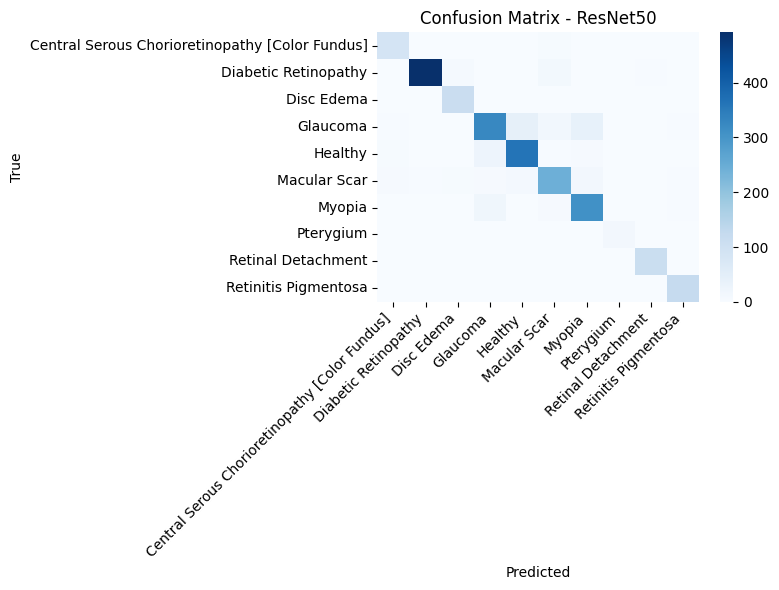

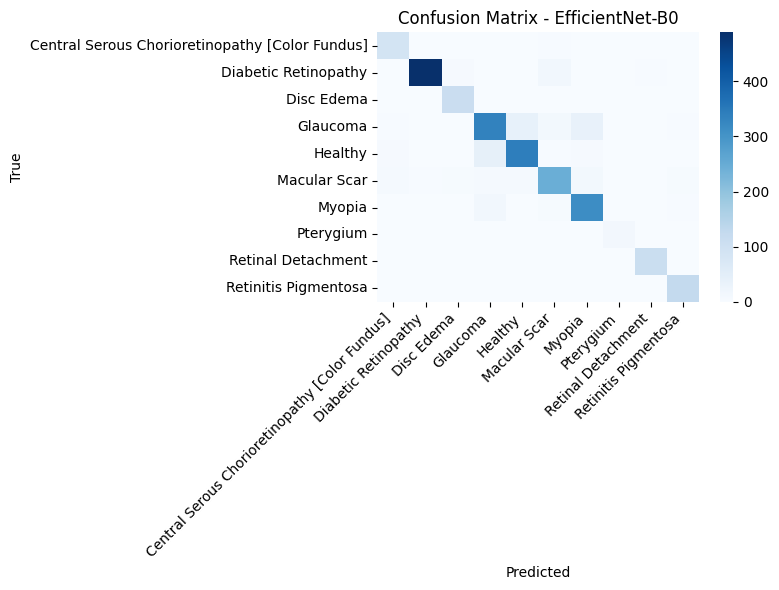

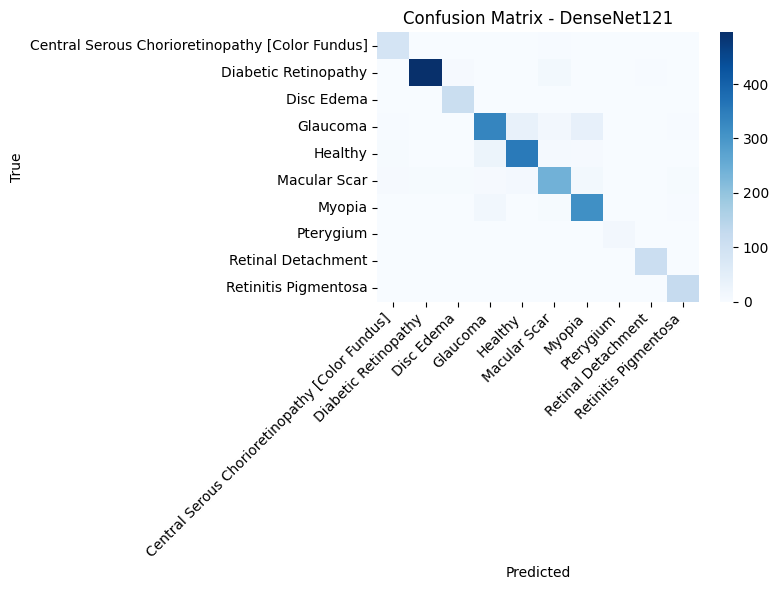

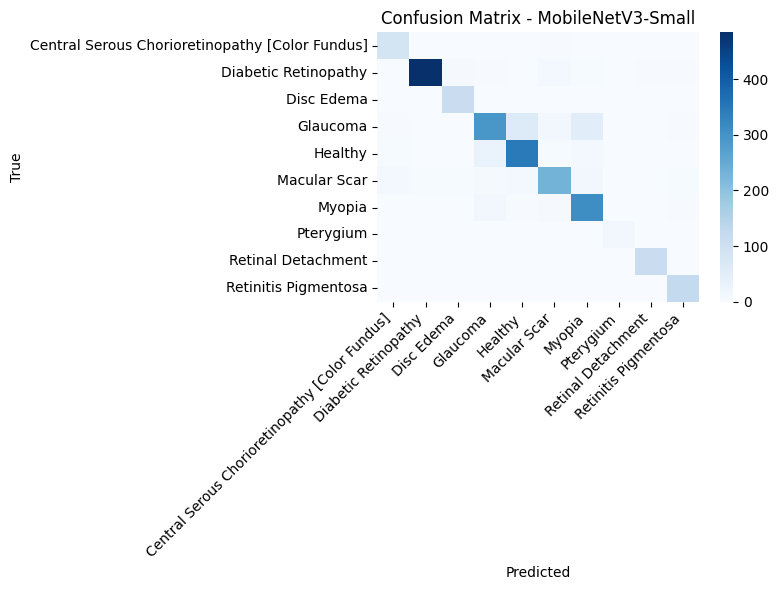

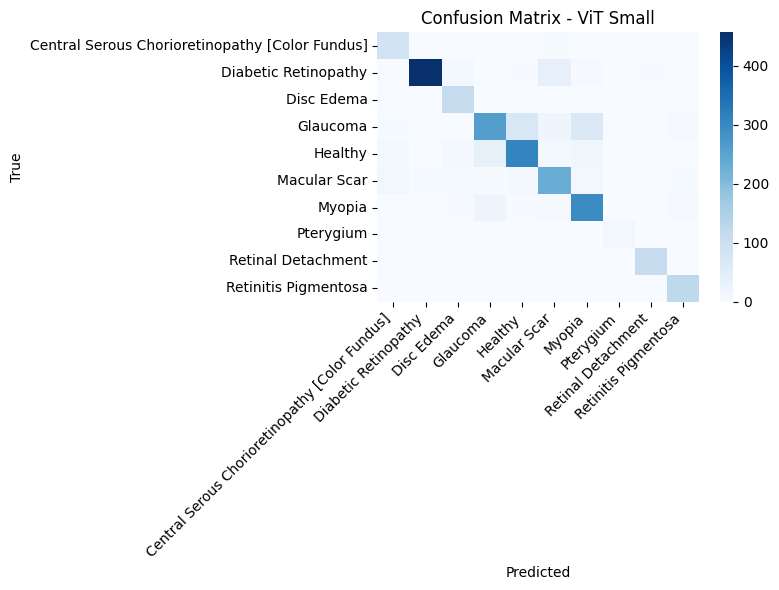

In [33]:
# 13) Plot confusion matrices for trained models
def plot_confusion_matrix(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=False, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


for m_name, (y_true, y_pred) in all_confusions.items():
    plot_confusion_matrix(y_true, y_pred, class_names, f"Confusion Matrix - {m_name}")


In [34]:
# 14) Single-image prediction helper
def preprocess_pil(pil_img, image_size=224):
    tfm = transforms.Compose([
        transforms.Resize((image_size, image_size)),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD),
    ])
    return tfm(pil_img.convert("RGB")).unsqueeze(0)


def predict_single(model, pil_img, image_size=224):
    model = model.to(device).eval()
    x = preprocess_pil(pil_img, image_size=image_size).to(device)
    with torch.no_grad():
        out = unwrap_logits(model(x))
        probs = torch.softmax(out, dim=1)[0]
        pred_idx = int(torch.argmax(probs).item())
    return class_names[pred_idx], float(probs[pred_idx].item()), probs.cpu().numpy()


Best model: DenseNet121


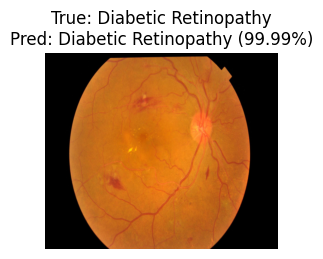

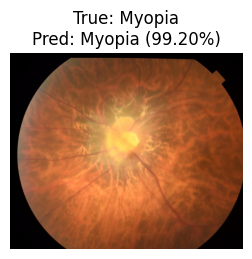

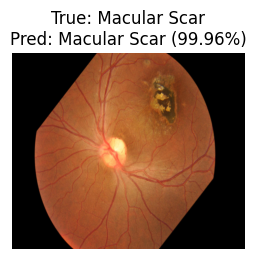

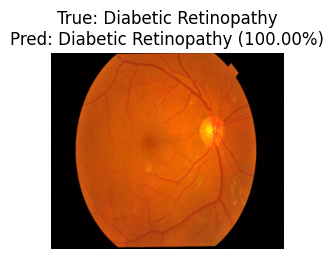

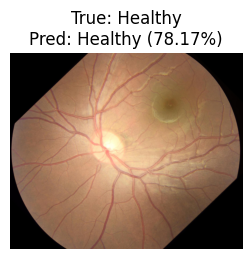

In [35]:
# 15) Quick qualitative check
best_row = results_df.iloc[0]
best_model_name = best_row["Model"]
best_model = best_models[best_model_name]
best_size = 224
print("Best model:", best_model_name)

sample_paths = test_df.sample(n=min(5, len(test_df)), random_state=SEED)["path"].tolist()
for p in sample_paths:
    img = Image.open(p).convert("RGB")
    pred_name, conf, _ = predict_single(best_model, img, image_size=best_size)
    true_name = Path(p).parent.name
    plt.figure(figsize=(3, 3))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"True: {true_name}\nPred: {pred_name} ({conf:.2%})")
    plt.show()


In [36]:
# 16) XAI (Grad-CAM++) setup
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


def tensor_to_np_img(x_3chw):
    arr = x_3chw.detach().cpu().permute(1, 2, 0).numpy()
    arr = arr * np.array(STD).reshape(1, 1, 3) + np.array(MEAN).reshape(1, 1, 3)
    return np.clip(arr, 0, 1)


def infer_cam_layer_and_reshape(model):
    # CNN backbones
    if hasattr(model, "layer4"):
        return model.layer4[-1], None
    if hasattr(model, "features"):
        try:
            return model.features[-1], None
        except Exception:
            pass

    # ViT-like models
    if hasattr(model, "blocks"):
        target_layer = model.blocks[-1].norm1

        def reshape_transform(tensor):
            # (B, tokens, C) -> (B, C, H, W)
            tensor = tensor[:, 1:, :]
            h = int((tensor.shape[1]) ** 0.5)
            return tensor.reshape(tensor.size(0), h, h, tensor.size(2)).permute(0, 3, 1, 2)

        return target_layer, reshape_transform

    raise ValueError("Unsupported model for Grad-CAM++ target inference.")


def explain_image_gradcam_pp(model, pil_img, image_size=224):
    model = model.to(device).eval()
    x = preprocess_pil(pil_img, image_size=image_size).to(device)
    with torch.no_grad():
        logits = unwrap_logits(model(x))
        pred_idx = int(logits.argmax(dim=1).item())

    target_layer, reshape_transform = infer_cam_layer_and_reshape(model)
    cam = GradCAMPlusPlus(model=model, target_layers=[target_layer], reshape_transform=reshape_transform)
    grayscale_cam = cam(input_tensor=x, targets=[ClassifierOutputTarget(pred_idx)])[0]

    original = tensor_to_np_img(x[0])
    overlay = show_cam_on_image(original, grayscale_cam, use_rgb=True)
    return pred_idx, original, overlay


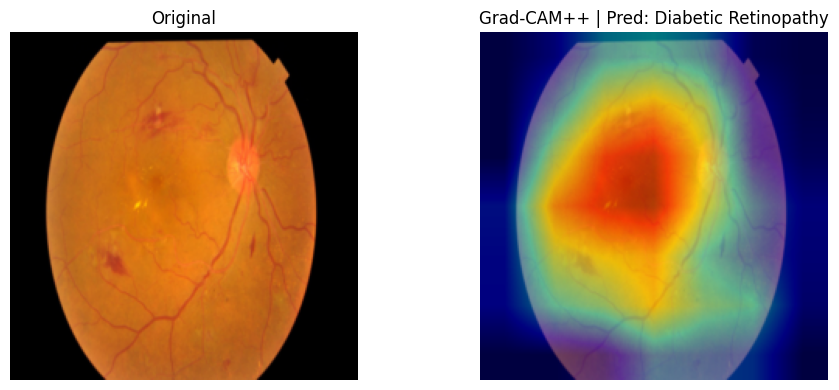

In [37]:
# 17) Run XAI on best model
img_path_for_xai = test_df.sample(n=1, random_state=SEED)["path"].iloc[0]
img_for_xai = Image.open(img_path_for_xai).convert("RGB")
pred_idx, original_np, cam_overlay = explain_image_gradcam_pp(best_model, img_for_xai, image_size=224)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(original_np)
axes[0].set_title("Original")
axes[0].axis("off")
axes[1].imshow(cam_overlay)
axes[1].set_title(f"Grad-CAM++ | Pred: {class_names[pred_idx]}")
axes[1].axis("off")
plt.tight_layout()
plt.show()


In [38]:
# 18) Federated Learning setup (manual FedAvg / FedProx simulation)
FED_CLIENTS = 3
FED_ROUNDS = 3
FED_LOCAL_EPOCHS = 1
FED_LR = 1e-4

# Use MobileNetV3-Small for FL stability and speed
def fl_model_ctor():
    return create_mobilenet_v3_small(NUM_CLASSES)


train_indices = np.arange(len(train_df))
np.random.seed(SEED)
np.random.shuffle(train_indices)
splits = np.array_split(train_indices, FED_CLIENTS)

client_datasets = []
for split in splits:
    client_df = train_df.iloc[split].reset_index(drop=True)
    client_datasets.append(EyeDiseaseDataset(client_df, transform=train_tfms))

print("Client sizes:", [len(ds) for ds in client_datasets])


Client sizes: [3790, 3790, 3789]


In [39]:
# 19) Federated helper functions
def get_params(model):
    return [v.detach().cpu().numpy() for _, v in model.state_dict().items()]


def set_params(model, params):
    sd = model.state_dict()
    new_sd = {}
    for k, v in zip(sd.keys(), params):
        new_sd[k] = torch.tensor(v, dtype=sd[k].dtype)
    model.load_state_dict(new_sd, strict=True)


def fedavg(param_list):
    n = len(param_list)
    layers = len(param_list[0])
    return [np.mean([param_list[i][j] for i in range(n)], axis=0) for j in range(layers)]


def train_client(global_params, client_dataset, fedprox_mu=0.0):
    model = fl_model_ctor().to(device)
    set_params(model, global_params)
    global_snapshot = [p.detach().clone() for p in model.parameters()]
    loader = DataLoader(client_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
    opt = torch.optim.AdamW(model.parameters(), lr=FED_LR)
    ce = nn.CrossEntropyLoss()
    model.train()

    for _ in range(FED_LOCAL_EPOCHS):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            out = unwrap_logits(model(x))
            loss = ce(out, y)
            if fedprox_mu > 0.0:
                prox = 0.0
                for p, gp in zip(model.parameters(), global_snapshot):
                    prox = prox + torch.sum((p - gp) ** 2)
                loss = loss + 0.5 * fedprox_mu * prox
            loss.backward()
            opt.step()

    return get_params(model)


def evaluate_global_params(params):
    model = fl_model_ctor().to(device)
    set_params(model, params)
    metrics = evaluate_model(model, val_loader)
    return metrics["accuracy"], metrics["f1"]


def run_federated(strategy_name, fedprox_mu=0.0):
    print(f"\n--- Running {strategy_name} ---")
    global_model = fl_model_ctor().to(device)
    global_params = get_params(global_model)
    hist = []
    for r in range(1, FED_ROUNDS + 1):
        local_updates = []
        for c_ds in client_datasets:
            local_updates.append(train_client(global_params, c_ds, fedprox_mu=fedprox_mu))
        global_params = fedavg(local_updates)
        acc, f1 = evaluate_global_params(global_params)
        hist.append({"round": r, "accuracy": acc, "f1": f1})
        print(f"Round {r}/{FED_ROUNDS} | val_acc={acc:.4f} | val_f1={f1:.4f}")

    final_model = fl_model_ctor().to(device)
    set_params(final_model, global_params)
    save_stub = strategy_name.lower().replace(" ", "_")
    final_path = MODEL_DIR / f"{save_stub}_final.pth"
    torch.save(
        {
            "architecture": "MobileNetV3-Small",
            "model_state_dict": final_model.state_dict(),
            "class_names": class_names,
            "image_size": IMG_SIZE,
            "mean": MEAN,
            "std": STD,
            "strategy": strategy_name,
            "history": hist,
        },
        final_path,
    )
    print("Saved federated model:", final_path)
    return hist, final_path


In [40]:
# 20) Run FedAvg and FedProx
fedavg_hist, fedavg_path = run_federated("FedAvg", fedprox_mu=0.0)
fedprox_hist, fedprox_path = run_federated("FedProx", fedprox_mu=0.01)

fed_hist_df = pd.DataFrame(
    [
        {"strategy": "FedAvg", **item}
        for item in fedavg_hist
    ]
    + [
        {"strategy": "FedProx", **item}
        for item in fedprox_hist
    ]
)
display(fed_hist_df)



--- Running FedAvg ---
Round 1/3 | val_acc=0.6634 | val_f1=0.6448
Round 2/3 | val_acc=0.7545 | val_f1=0.7505
Round 3/3 | val_acc=0.7915 | val_f1=0.7871
Saved federated model: D:\CSE Code\CSE498R\CSE498R models\fedavg_final.pth

--- Running FedProx ---
Round 1/3 | val_acc=0.6642 | val_f1=0.6402
Round 2/3 | val_acc=0.7533 | val_f1=0.7436
Round 3/3 | val_acc=0.7898 | val_f1=0.7855
Saved federated model: D:\CSE Code\CSE498R\CSE498R models\fedprox_final.pth


,strategy,round,accuracy,f1
0,FedAvg,1,0.663383,0.644785
1,FedAvg,2,0.754516,0.750461
2,FedAvg,3,0.791461,0.787064
3,FedProx,1,0.664204,0.640212
4,FedProx,2,0.753284,0.743570
5,FedProx,3,0.789819,0.785468


In [41]:
# 21) Final artifact summary
print("=== Saved model files ===")
for p in sorted(MODEL_DIR.glob("*")):
    print(p.name)

artifact_df = pd.DataFrame(
    {
        "Artifact": [p.name for p in sorted(MODEL_DIR.glob("*"))],
        "Path": [str(p) for p in sorted(MODEL_DIR.glob("*"))],
    }
)
display(artifact_df)


=== Saved model files ===
densenet121_best.pth
densenet121_bundle.pth
efficientnet_b0_best.pth
efficientnet_b0_bundle.pth
fedavg_final.pth
fedprox_final.pth
mobilenetv3_small_best.pth
mobilenetv3_small_bundle.pth
resnet50_best.pth
resnet50_bundle.pth
vit_small_best.pth
vit_small_bundle.pth


,Artifact,Path
0,densenet121_best.pth,D:\CSE Code\CSE498R\CSE498R models\densenet121...
1,densenet121_bundle.pth,D:\CSE Code\CSE498R\CSE498R models\densenet121...
2,efficientnet_b0_best.pth,D:\CSE Code\CSE498R\CSE498R models\efficientne...
3,efficientnet_b0_bundle.pth,D:\CSE Code\CSE498R\CSE498R models\efficientne...
4,fedavg_final.pth,D:\CSE Code\CSE498R\CSE498R models\fedavg_fina...
5,fedprox_final.pth,D:\CSE Code\CSE498R\CSE498R models\fedprox_fin...
6,mobilenetv3_small_best.pth,D:\CSE Code\CSE498R\CSE498R models\mobilenetv3...
7,mobilenetv3_small_bundle.pth,D:\CSE Code\CSE498R\CSE498R models\mobilenetv3...
8,resnet50_best.pth,D:\CSE Code\CSE498R\CSE498R models\resnet50_be...
9,resnet50_bundle.pth,D:\CSE Code\CSE498R\CSE498R models\resnet50_bu...
